In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.Retrieval import Retrieval
# from src.utils.util import save_sensor_dict

In [3]:
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default'
TAU1D = EXPERIMENT / 'tau_1D'
r = Retrieval(EXPERIMENT)
r.load_retrieval()

In [4]:
tausA = np.linspace(0, 4.75, 20)
tausB = np.logspace(np.log10(5), 2, 40)
taus = np.append(tausA, tausB)
wavelength = 0.67
cb = 0.4
ct = 1.1
LUT_outfile = TAU1D / 'LUT_1Dtau.nc'
# LUT_outfile = TAU1D / 'LUT_1Dtau_400_1100.nc'
r.generate_1D_LUT(wavelength, taus, cb, ct, LUT_outfile)
# outfile = TAU1D / 'tau1D_400_1100.nc'
outfile = TAU1D / 'tau1D.nc'
r.retrieve_1D_tau(outfile)

In [5]:
brf_ths = {
    'DF': 0.120,
    'CF': 0.076,
    'BF': 0.054,
    'AF': 0.044,
    'AN': 0.040,
    'AA': 0.045,
    'BA': 0.052,
    'CA': 0.068,
    'DA': 0.092
}
r.add_threshold_mask(r.obs, 'MISR', 'threshold_mask', 'brf', brf_ths)
r.add_threshold_mask(r.sensors_retrieval, 'MISR', 'tau_mask', 'optical_depth', 0.3)
r.add_ray_containment_mask(mask_name='ray_containment')

In [6]:
sensor_i = 4
# mask_name1 = 'threshold_mask'
mask_name1 = 'tau_mask'
mask_name2 = 'ray_containment'
mask1 = r.masks['MISR']['sensor_list'][sensor_i][mask_name1]
mask2 = r.masks['MISR']['sensor_list'][sensor_i][mask_name2]
mask_cond = np.logical_and(mask1 == 1, mask2 == 2)

attr = 'optical_depth'

cam1D = r.obs['MISR']['sensor_list'][sensor_i]
cam3D = r.sensors_retrieval['MISR']['sensor_list'][sensor_i]

z1D = np.nan_to_num(cam1D[attr])[mask_cond]
z3D = np.nan_to_num(cam3D[attr])[mask_cond]

taubar1D = np.mean(z1D)
taubar3D = np.mean(z3D)

In [7]:
print(f'AT3D cloud-mean {attr}: {taubar3D}')
print(f'  1D cloud-mean {attr}: {taubar1D}')
print(f'Difference of 3D relative to 1D: {100*(taubar3D - taubar1D)/taubar1D:.2f}%')
print(f'Difference of 1D relative to 3D: {100*(taubar1D - taubar3D)/taubar3D:.2f}%')

AT3D cloud-mean optical_depth: 1.7994365094960105
  1D cloud-mean optical_depth: 1.6735145140157437
Difference of 3D relative to 1D: 7.52%
Difference of 1D relative to 3D: -7.00%


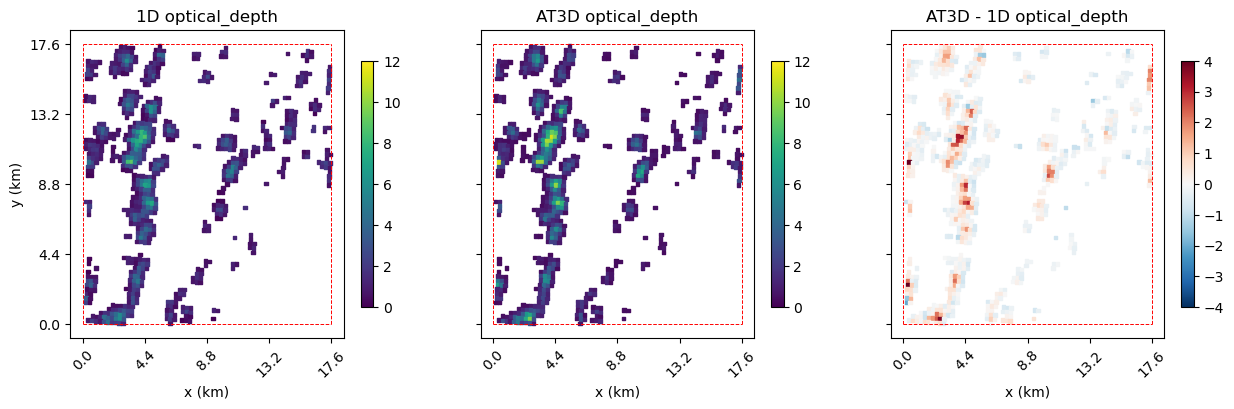

In [8]:
f, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

# tau_kwargs = {
#     'levels':np.arange(0.0,12.1,0.1)
# }
# tau_diff_kwargs = {
#     'levels':np.arange(-3,3.02,0.1),
#     'cmap':'RdBu_r'
# }
# p1 = ax[0].tricontourf(cam1D.ray_x, cam1D.ray_y, z1D, **tau_kwargs)
# p2 = ax[1].tricontourf(cam3D.ray_x, cam3D.ray_y, z3D, **tau_kwargs)
# p3 = ax[2].tricontourf(cam1D.ray_x, cam1D.ray_y, z3D - z1D, **tau_diff_kwargs)

scat_kwargs = {
    's':6,
    'marker':'s',
    'vmin':0,
    'vmax':12
}
scat_diff_kwargs = scat_kwargs.copy()
scat_diff_kwargs['cmap'] = 'RdBu_r'
scat_diff_kwargs['vmin'] = -4
scat_diff_kwargs['vmax'] = 4
p1 = ax[0].scatter(cam1D.ray_x.data[mask_cond], cam1D.ray_y.data[mask_cond], c=z1D, **scat_kwargs)
p2 = ax[1].scatter(cam3D.ray_x.data[mask_cond], cam3D.ray_y.data[mask_cond], c=z3D, **scat_kwargs)
p3 = ax[2].scatter(cam1D.ray_x.data[mask_cond], cam1D.ray_y.data[mask_cond], c=z3D - z1D, **scat_diff_kwargs)

plt.colorbar(p1, ax=ax[0], shrink=0.8)
plt.colorbar(p2, ax=ax[1], shrink=0.8)
plt.colorbar(p3, ax=ax[2], shrink=0.8)

ax[0].set_title(f'1D {attr}')
ax[1].set_title(f'AT3D {attr}')
ax[2].set_title(f'AT3D - 1D {attr}')
ax[0].set_ylabel('y (km)')

ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
box_kwargs = {
    'c':'r',
    'ls': '--',
    'lw': 0.7
}
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [0, 0], **box_kwargs)
    a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
    a.set_xlabel('x (km)')
    # a.set_xlim([0,17.6])
    # a.set_ylim([0,17.6])

Text(0, 0.5, 'AT3D Retrieved optical_depth')

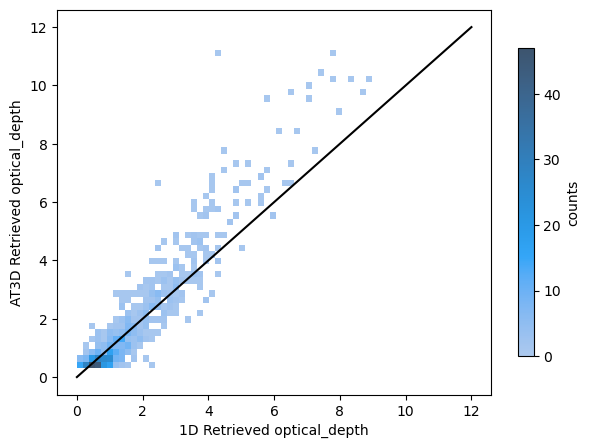

In [9]:
f, ax = plt.subplots(1, 1, figsize=(7, 5))
sns.histplot(x=z1D, y=z3D, ax=ax, bins=49, cbar=True, cbar_kws=dict(shrink=.8, label='counts'))
ax.plot([0, 12], [0, 12], 'k')
ax.set_xlabel(f'1D Retrieved {attr}')
ax.set_ylabel(f'AT3D Retrieved {attr}')

/tmp/ipykernel_3611642/12169052.py:20: RuntimeWarning: divide by zero encountered in divide
  ax[1, 0].hist(100*(z3D-z1D) / z1D, label='% difference 3D rel to 1D', **hist_kwargs)


Text(0.5, 0, '% difference 1D rel to 3D')

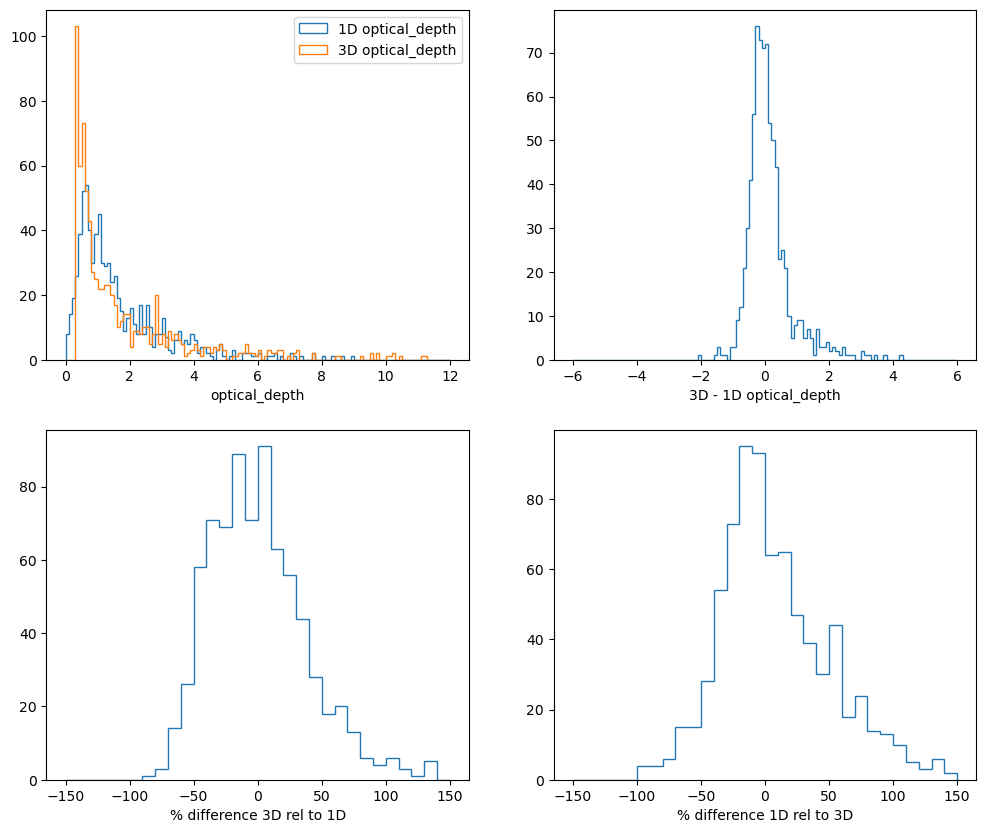

In [10]:
f, ax = plt.subplots(2, 2, figsize=(12, 10), sharex=False, sharey=False)

hist_kwargs = {
    'bins':np.arange(0, 12.01, 0.1),
    'histtype':'step',
    'log': False,
    'density': False
}

ax[0, 0].hist(z1D, label=f'1D {attr}', **hist_kwargs)
ax[0, 0].hist(z3D, label=f'3D {attr}', **hist_kwargs)
ax[0, 0].legend()
ax[0, 0].set_xlabel(f'{attr}')

hist_kwargs['bins'] = np.arange(-6, 6.1, 0.1)
ax[0, 1].hist(z3D-z1D, label=f'3D - 1D {attr}', **hist_kwargs)
ax[0, 1].set_xlabel(f'3D - 1D {attr}')

hist_kwargs['bins'] = np.arange(-150, 150.1, 10.0)
ax[1, 0].hist(100*(z3D-z1D) / z1D, label='% difference 3D rel to 1D', **hist_kwargs)
ax[1, 0].set_xlabel('% difference 3D rel to 1D')
ax[1, 1].hist(100*(z1D-z3D) / z3D, label='% difference 1D rel to 3D', **hist_kwargs)
ax[1, 1].set_xlabel('% difference 1D rel to 3D')